Compare SHAP and LIME explanations by performing an in-depth statistical correlation analysis, manually quantifying consistency across methods, and identifying limitations in each approach for different feature types.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import itertools
import math

from scipy.stats import pearsonr, spearmanr
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier

df = pd.read_csv("heart_disease_train.csv")

features = ["age", "trestbps", "chol", "thalach", "oldpeak"]
target = "target"

for col in features + [target]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=features + [target]).copy()

X = df[features]
y = df[target].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model = make_pipeline(
    StandardScaler(),
    RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        class_weight="balanced",
        random_state=42
    )
)

model.fit(X_train, y_train)

background = X_train.sample(
    n=min(20, len(X_train)),
    random_state=42
).reset_index(drop=True)

patients = X_test.iloc[:min(20, len(X_test))].copy()

print("Model trained.")
print("Patients to explain:", len(patients))
print("Features:", features)

Model trained.
Patients to explain: 16
Features: ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']


In [2]:
def predict_probability(data):
    data = pd.DataFrame(data, columns=features)
    return model.predict_proba(data)[:, 1]


def manual_shapley_values(patient, background):
    n = len(features)
    result = np.zeros(n)
    patient_values = patient[features].to_numpy(dtype=float)

    for i in range(n):
        other_features = [j for j in range(n) if j != i]

        for size in range(n):
            for subset in itertools.combinations(other_features, size):
                weight = (
                    math.factorial(size)
                    * math.factorial(n - size - 1)
                    / math.factorial(n)
                )

                without_i = background.copy()
                with_i = background.copy()

                for j in subset:
                    without_i.iloc[:, j] = patient_values[j]
                    with_i.iloc[:, j] = patient_values[j]

                with_i.iloc[:, i] = patient_values[i]

                p_with = predict_probability(with_i).mean()
                p_without = predict_probability(without_i).mean()

                result[i] += weight * (p_with - p_without)

    return result


print("Manual SHAP function ready.")

Manual SHAP function ready.


In [3]:
def manual_lime_contributions(
    patient,
    n_samples=1500,
    seed=42
):
    rng = np.random.default_rng(seed)

    means = X_train.mean().to_numpy()
    stds = X_train.std().to_numpy()
    stds = np.where(stds == 0, 1.0, stds)

    x = patient[features].to_numpy(dtype=float)

    noise = rng.normal(size=(n_samples, len(features)))
    samples = x + noise * stds

    samples = np.clip(
        samples,
        X_train.min().to_numpy(),
        X_train.max().to_numpy()
    )

    synthetic = pd.DataFrame(samples, columns=features)
    probabilities = predict_probability(synthetic)

    # Standardize the samples.
    Z = (samples - means) / stds
    z_patient = (x - means) / stds

    distances = np.sqrt(np.sum((Z - z_patient) ** 2, axis=1))
    kernel_width = 0.75 * np.sqrt(len(features))
    weights = np.exp(-(distances ** 2) / (kernel_width ** 2))

    design = np.column_stack([np.ones(n_samples), Z])

    # Weighted ridge regression, with no penalty on the intercept.
    weighted_design = design * np.sqrt(weights[:, None])
    weighted_y = probabilities * np.sqrt(weights)

    penalty = np.eye(design.shape[1])
    penalty[0, 0] = 0

    coefficients = np.linalg.solve(
        weighted_design.T @ weighted_design + penalty,
        weighted_design.T @ weighted_y
    )

    local_mean = np.average(Z, axis=0, weights=weights)

    # Contribution relative to the weighted local reference.
    contributions = coefficients[1:] * (z_patient - local_mean)

    return contributions


print("Manual LIME function ready.")

Manual LIME function ready.


In [4]:
shap_results = []
lime_results = []

for idx, patient in patients.iterrows():
    shap_values = manual_shapley_values(patient, background)

    lime_values = manual_lime_contributions(
        patient,
        n_samples=1500,
        seed=42
    )

    for j, feature in enumerate(features):
        shap_results.append({
            "Patient": idx,
            "Feature": feature,
            "SHAP": shap_values[j]
        })

        lime_results.append({
            "Patient": idx,
            "Feature": feature,
            "LIME": lime_values[j]
        })

shap_df = pd.DataFrame(shap_results)
lime_df = pd.DataFrame(lime_results)

comparison = shap_df.merge(
    lime_df,
    on=["Patient", "Feature"]
)

print(comparison.head(10))

   Patient   Feature      SHAP      LIME
0       49       age -0.403625 -0.043839
1       49  trestbps -0.070833 -0.000195
2       49      chol  0.045375  0.000749
3       49   thalach -0.005458  0.000128
4       49   oldpeak  0.048542  0.000002
5        1       age  0.051625 -0.001242
6        1  trestbps -0.025417 -0.000722
7        1      chol -0.199958 -0.000765
8        1   thalach -0.090917 -0.015790
9        1   oldpeak  0.048667 -0.001914


In [5]:
def safe_correlation(a, b, method="pearson"):
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)

    if len(a) < 2 or np.std(a) == 0 or np.std(b) == 0:
        return np.nan

    if method == "pearson":
        return pearsonr(a, b).statistic

    return spearmanr(a, b).statistic


patient_correlations = []

for patient_id, group in comparison.groupby("Patient"):
    patient_correlations.append({
        "Patient": patient_id,
        "Pearson": safe_correlation(
            group["SHAP"], group["LIME"], "pearson"
        ),
        "Spearman": safe_correlation(
            group["SHAP"], group["LIME"], "spearman"
        )
    })

patient_corr_df = pd.DataFrame(patient_correlations)

pooled_pearson = safe_correlation(
    comparison["SHAP"], comparison["LIME"], "pearson"
)

pooled_spearman = safe_correlation(
    comparison["SHAP"], comparison["LIME"], "spearman"
)

print("Pooled Pearson correlation:", round(pooled_pearson, 4))
print("Pooled Spearman correlation:", round(pooled_spearman, 4))

print("\nPatient-level correlations:")
print(patient_corr_df.round(4).to_string(index=False))

print("\nMean patient-level Pearson:",
      round(patient_corr_df["Pearson"].mean(), 4))

print("Mean patient-level Spearman:",
      round(patient_corr_df["Spearman"].mean(), 4))

Pooled Pearson correlation: 0.7215
Pooled Spearman correlation: 0.4596

Patient-level correlations:
 Patient  Pearson  Spearman
       1   0.2046      -0.1
      13   0.0050      -0.5
      23   0.0310      -0.1
      24   0.4787       0.3
      28   0.6861       0.3
      35   0.5509       0.4
      36   0.6882       0.5
      39  -0.0429       0.0
      42   0.7959       0.9
      47   0.9655       0.8
      49   0.9693       0.7
      56   0.5869       0.7
      66   0.5747       0.6
      67  -0.2172      -0.3
      72   0.8549       0.2
      76   0.7566       0.3

Mean patient-level Pearson: 0.493
Mean patient-level Spearman: 0.2938


In [6]:
rank_results = []

for patient_id, group in comparison.groupby("Patient"):
    shap_rank = group.set_index("Feature")["SHAP"].abs().rank(
        ascending=False, method="average"
    )
    lime_rank = group.set_index("Feature")["LIME"].abs().rank(
        ascending=False, method="average"
    )

    shap_top = set(shap_rank.nsmallest(3).index)
    lime_top = set(lime_rank.nsmallest(3).index)

    sign_agreement = np.mean(
        np.sign(group["SHAP"]) == np.sign(group["LIME"])
    )

    top_overlap = len(shap_top & lime_top) / len(shap_top | lime_top)

    rank_results.append({
        "Patient": patient_id,
        "Top-3 Overlap (Jaccard)": top_overlap,
        "Sign Agreement": sign_agreement,
        "Rank Correlation": safe_correlation(
            shap_rank.reindex(features),
            lime_rank.reindex(features),
            "spearman"
        )
    })

agreement_df = pd.DataFrame(rank_results)

print(agreement_df.round(4).to_string(index=False))

print("\nAverage top-3 overlap:",
      round(agreement_df["Top-3 Overlap (Jaccard)"].mean(), 4))

print("Average sign agreement:",
      round(agreement_df["Sign Agreement"].mean(), 4))

print("Average rank correlation:",
      round(agreement_df["Rank Correlation"].mean(), 4))

 Patient  Top-3 Overlap (Jaccard)  Sign Agreement  Rank Correlation
       1                      0.5             0.6               0.3
      13                      0.5             0.6              -0.3
      23                      0.5             0.4               0.3
      24                      0.5             0.4              -0.3
      28                      0.5             0.8               0.3
      35                      1.0             0.8               0.7
      36                      0.5             0.8               0.1
      39                      0.2             0.4              -0.6
      42                      0.5             0.8               0.5
      47                      1.0             1.0               0.8
      49                      0.5             0.8               0.5
      56                      0.2             0.4              -0.1
      66                      0.5             0.4               0.2
      67                      0.5             0.

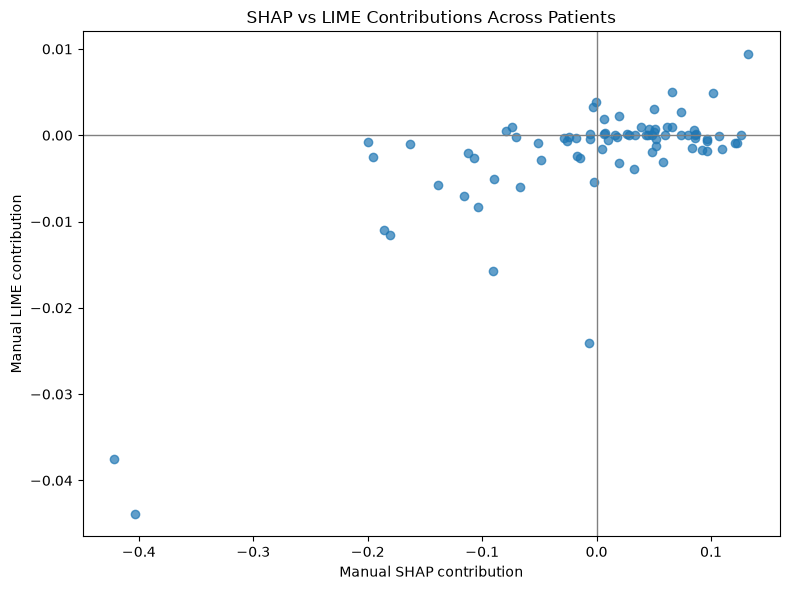

In [7]:
plt.figure(figsize=(8, 6))

plt.scatter(
    comparison["SHAP"],
    comparison["LIME"],
    alpha=0.7
)

plt.axhline(0, color="grey", linewidth=1)
plt.axvline(0, color="grey", linewidth=1)

plt.xlabel("Manual SHAP contribution")
plt.ylabel("Manual LIME contribution")
plt.title("SHAP vs LIME Contributions Across Patients")

plt.tight_layout()
plt.show()

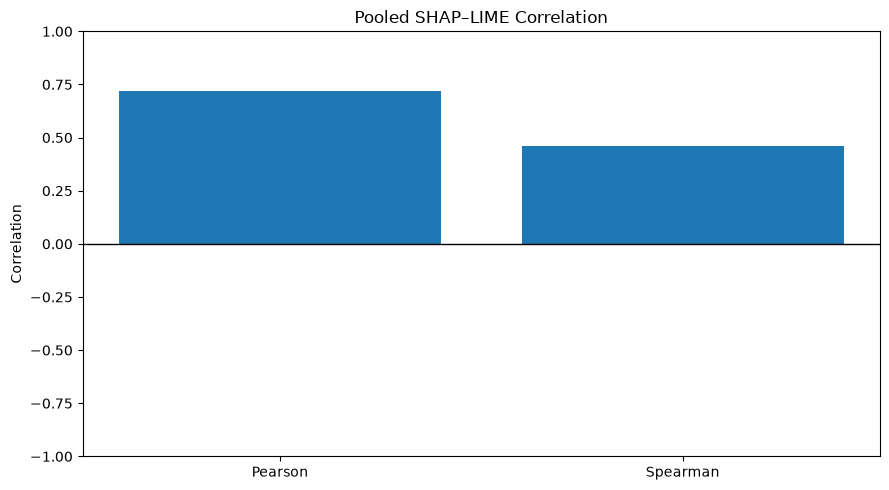

In [8]:
plt.figure(figsize=(9, 5))

plt.bar(
    ["Pearson", "Spearman"],
    [pooled_pearson, pooled_spearman]
)

plt.ylim(-1, 1)
plt.ylabel("Correlation")
plt.title("Pooled SHAP–LIME Correlation")
plt.axhline(0, color="black", linewidth=1)
plt.tight_layout()
plt.show()

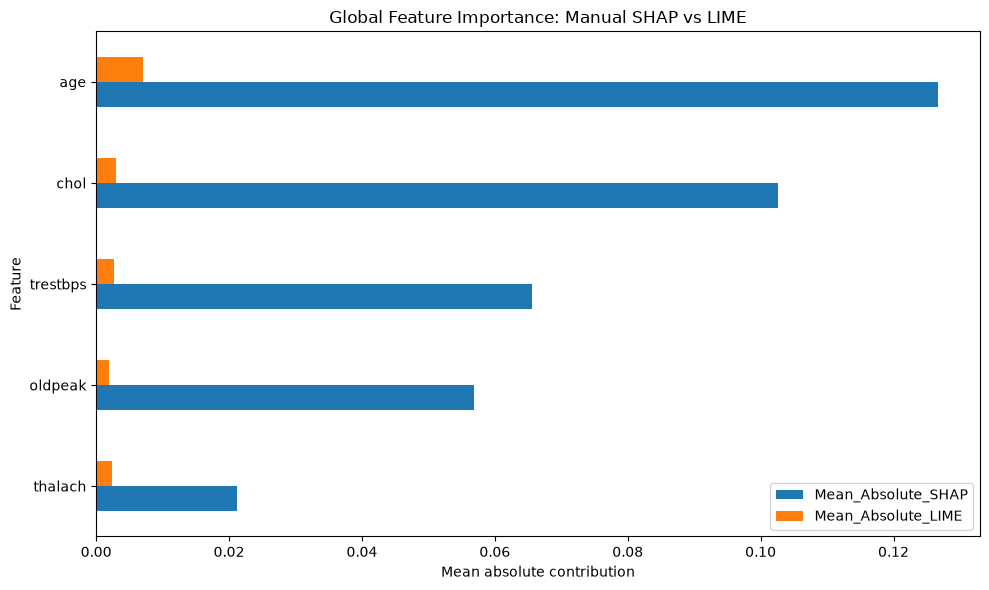

          Mean_Absolute_SHAP  Mean_Absolute_LIME
Feature                                         
age                  0.12668             0.00704
chol                 0.10259             0.00294
trestbps             0.06559             0.00273
oldpeak              0.05693             0.00194
thalach              0.02124             0.00231


In [9]:
importance_df = comparison.groupby("Feature").agg(
    Mean_Absolute_SHAP=("SHAP", lambda x: x.abs().mean()),
    Mean_Absolute_LIME=("LIME", lambda x: x.abs().mean())
)

importance_df = importance_df.sort_values(
    "Mean_Absolute_SHAP",
    ascending=True
)

importance_df.plot(
    kind="barh",
    figsize=(10, 6),
    title="Global Feature Importance: Manual SHAP vs LIME"
)

plt.xlabel("Mean absolute contribution")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

print(importance_df.sort_values(
    "Mean_Absolute_SHAP", ascending=False
).round(5))

          Mean Contribution  Standard Deviation  Mean Absolute Contribution
age                -0.04316             0.00287                     0.04316
chol                0.00080             0.00251                     0.00190
trestbps            0.00134             0.00140                     0.00167
thalach             0.00008             0.00028                     0.00018
oldpeak             0.00003             0.00012                     0.00008


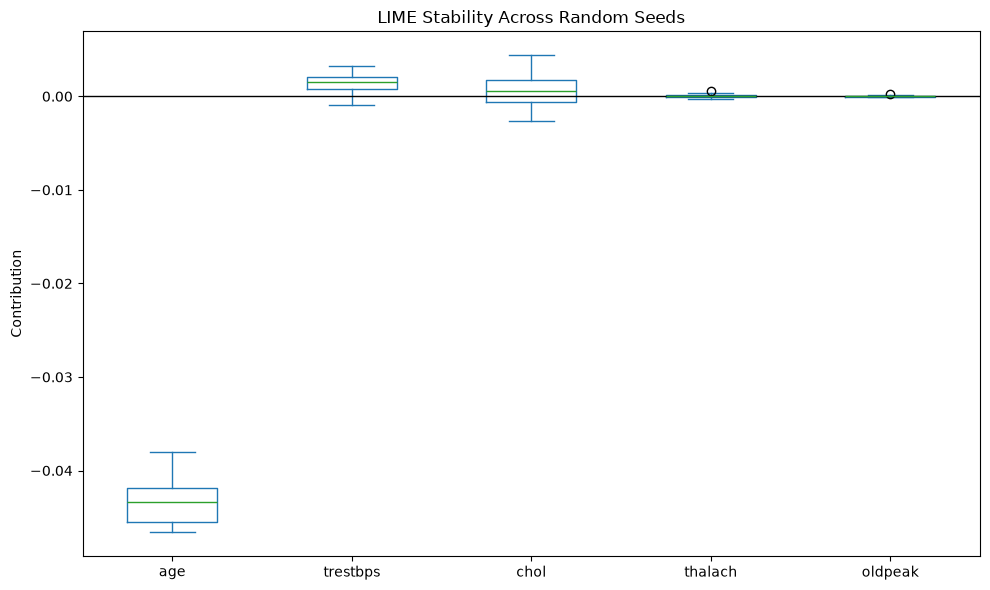

In [10]:
selected_patient = patients.iloc[0]

lime_runs = []

for seed in [10, 20, 30, 40, 50, 60, 70, 80]:
    values = manual_lime_contributions(
        selected_patient,
        n_samples=1500,
        seed=seed
    )

    lime_runs.append(values)

lime_stability = pd.DataFrame(
    lime_runs,
    columns=features
)

stability_summary = pd.DataFrame({
    "Mean Contribution": lime_stability.mean(),
    "Standard Deviation": lime_stability.std(),
    "Mean Absolute Contribution": lime_stability.abs().mean()
}).sort_values("Mean Absolute Contribution", ascending=False)

print(stability_summary.round(5))

lime_stability.plot(
    kind="box",
    figsize=(10, 6),
    title="LIME Stability Across Random Seeds"
)

plt.axhline(0, color="black", linewidth=1)
plt.ylabel("Contribution")
plt.tight_layout()
plt.show()

In [11]:
print("SHAP vs LIME comparison summary")
print("--------------------------------")

print("Pooled Pearson:", round(pooled_pearson, 4))
print("Pooled Spearman:", round(pooled_spearman, 4))

print(
    "Mean top-3 overlap:",
    round(agreement_df["Top-3 Overlap (Jaccard)"].mean(), 4)
)

print(
    "Mean sign agreement:",
    round(agreement_df["Sign Agreement"].mean(), 4)
)

print("\nHighest average absolute SHAP contribution:")
print(importance_df["Mean_Absolute_SHAP"].idxmax())

print("Highest average absolute LIME contribution:")
print(importance_df["Mean_Absolute_LIME"].idxmax())

print("\nUse the printed metrics and plots to write your conclusions.")

SHAP vs LIME comparison summary
--------------------------------
Pooled Pearson: 0.7215
Pooled Spearman: 0.4596
Mean top-3 overlap: 0.525
Mean sign agreement: 0.65

Highest average absolute SHAP contribution:
age
Highest average absolute LIME contribution:
age

Use the printed metrics and plots to write your conclusions.
